In [1]:
import os

In [2]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [3]:
def load_raw_gmsh_nodes(file_path):
    nodes = []
    reading_nodes = False
    
    with open(file_path, 'r') as f:
        for line in f:
            line = line.strip()
            if line == "$Nodes":
                reading_nodes = True
                next(f) # Skip the line containing the total no. of nodes
                continue
            if line == "$EndNodes":
                reading_nodes = False
                break
            
            if reading_nodes:
                parts = line.split()
                # MSH 2.2 format for a node line:
                if len(parts) == 4:
                    try:
                        x = float(parts[1])
                        y = float(parts[2])
                        z = float(parts[3])
                        nodes.append([x, y, z])
                    except ValueError:
                        continue
                    
    return np.array(nodes)
                

1. Reading the .msh file and assigning the node coords
2. Check wheather the imported data matches the original data or not.

Successfully extracted 51484 raw node coords directly.

Raw Geometric Bounds Check
X range: [-501.0000 to -13.1421]
Y range: [-303.9914 to -89.9647]
Z range: [-0.1199 to 171.3792]


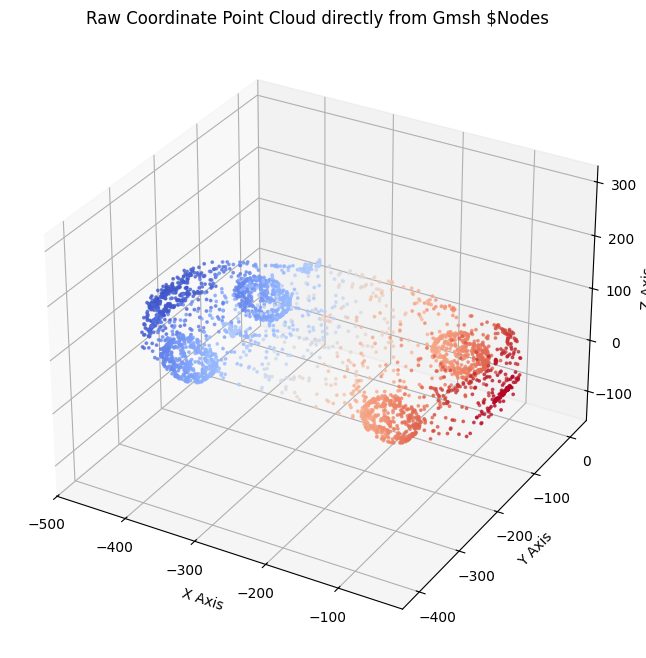

In [4]:
mesh_file = "assembly.msh"
try:
    all_points = load_raw_gmsh_nodes(mesh_file)
    print(f"Successfully extracted {len(all_points)} raw node coords directly.")
except Exception as e:
    print(f"Error reading file directly: {e}")
    all_points = np.array([])
    
if len(all_points) > 0:
    # 2. Print exact geometric extreme bounds
    print("\n" + "="*40)
    print("Raw Geometric Bounds Check")
    print("="*40)
    print(f"X range: [{all_points[:, 0].min():.4f} to {all_points[:, 0].max():.4f}]")
    print(f"Y range: [{all_points[:, 1].min():.4f} to {all_points[:, 1].max():.4f}]")
    print(f"Z range: [{all_points[:, 2].min():.4f} to {all_points[:, 2].max():.4f}]")
    print("="*40)
        
    # 3. Downsample to safely plot without lagging
    downsample_rate = max(1, len(all_points) // 3000)
    plot_nodes = all_points[::downsample_rate]
    
    # 4. Generating the direct Point distribution plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    scatter  = ax.scatter(
        plot_nodes[:, 0],
        plot_nodes[:, 1],
        plot_nodes[:, 2],
        c=plot_nodes[:, 0],# Color profile mapped across X-axis variation
        cmap='coolwarm',
        s=3,
        alpha=0.7
    )
    ax.set_title("Raw Coordinate Point Cloud directly from Gmsh $Nodes", fontsize=12)
    ax.set_xlabel("X Axis")
    ax.set_ylabel("Y Axis")
    ax.set_zlabel("Z Axis")
    
    # Force equal aspect ratio display so it's not distorted visually
    max_range = np.array([plot_nodes[:,0].max()-plot_nodes[:,0].min(), 
                          plot_nodes[:,1].max()-plot_nodes[:,1].min(), 
                          plot_nodes[:,2].max()-plot_nodes[:,2].min()]).max() / 2.0
    mid_x = (plot_nodes[:,0].max()+plot_nodes[:,0].min()) * 0.5
    mid_y = (plot_nodes[:,1].max()+plot_nodes[:,1].min()) * 0.5
    mid_z = (plot_nodes[:,2].max()+plot_nodes[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)

    plt.show()

    
    
    

Extract the points and dynamically calculate the bounding box of the model

In [5]:
mesh_file = "assembly.msh"
model_points = load_raw_gmsh_nodes(mesh_file)

x_min, x_max = model_points[:, 0].min(), model_points[:, 0].max()
y_min, y_max = model_points[:, 1].min(), model_points[:, 1].max()
z_min, z_max = model_points[:, 2].min(), model_points[:, 2].max()

L = x_max - x_min # Length of the model along flow direction X
H = y_max - y_min  # Width of the model along Y
W = z_max - z_min  # Height of the model along Z

print(f"Model dimensions detected: Length={L:.2f}, Height={W:.2f}, Width={H:.2f}")

Model dimensions detected: Length=487.86, Height=171.50, Width=214.03


Defining the Wind Tunnel Box Dimensions


In [6]:
tunnel_xmin = x_min - (0.5 * L)  # 0.5L upstream inlet
tunnel_xmax = x_max + (0.5 * L)  # 0.5L downstream outlet
tunnel_ymin = y_min              # Floor sits exactly at the bottom of the model
tunnel_ymax = y_max + (1.0 * H)  # 1.0H ceiling clearance
tunnel_zmin = z_min  # left side wall
tunnel_zmax = z_max + (0.5 * W)  # 0.5W right side wall


Create the deepxde mathematical bounding geometry for tunnel and converting the model points to a PointCloud Geometry

In [7]:
wind_tunnel_box = dde.geometry.Cuboid(
    [tunnel_xmin, tunnel_ymin, tunnel_zmin],
    [tunnel_xmax, tunnel_ymax, tunnel_zmax]
)

model_geom = dde.geometry.PointCloud(points=model_points, boundary_points=model_points)

EXCLUDE MODEL: Create Fluid Domain via Subtraction (Wind Tunnel minus Model)

In [8]:
fluid_domain = dde.geometry.CSGDifference(wind_tunnel_box, model_geom)

Defining a 3D Incompressible Navier-Stokes Equations with a Reynold's number 500

In [9]:
def navier_stokes_3d(x, y):
    re = 500.0 
    nu = 1.0 / re 
    u, v, w, p = y[:, 0:1], y[:, 1:2], y[:, 2:3], y[:, 3:4]

    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1)
    du_z = dde.grad.jacobian(y, x, i=0, j=2)
    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    dv_z = dde.grad.jacobian(y, x, i=1, j=2)
    dw_x = dde.grad.jacobian(y, x, i=2, j=0)
    dw_y = dde.grad.jacobian(y, x, i=2, j=1)
    dw_z = dde.grad.jacobian(y, x, i=2, j=2)
    dp_x = dde.grad.jacobian(y, x, i=3, j=0)
    dp_y = dde.grad.jacobian(y, x, i=3, j=1)
    dp_z = dde.grad.jacobian(y, x, i=3, j=2)

    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    du_zz = dde.grad.hessian(y, x, component=0, i=2, j=2)
    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    dv_zz = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dw_xx = dde.grad.hessian(y, x, component=2, i=0, j=0)
    dw_yy = dde.grad.hessian(y, x, component=2, i=1, j=1)
    dw_zz = dde.grad.hessian(y, x, component=2, i=2, j=2)

    continuity = du_x + dv_y + dw_z
    x_momentum = (u * du_x + v * du_y + w * du_z) + dp_x - nu * (du_xx + du_yy + du_zz)
    y_momentum = (u * dv_x + v * dv_y + w * dv_z) + dp_y - nu * (dv_xx + dv_yy + dv_zz)
    z_momentum = (u * dw_x + v * dw_y + w * dw_z) + dp_z - nu * (dw_xx + dw_yy + dw_zz)

    return [continuity, x_momentum, y_momentum, z_momentum]


Defining Wind Tunnel Boundary Filters

In [10]:
def boundary_inlet(x, on_boundary):
    return on_boundary and np.isclose(x[0], tunnel_xmin)

def boundary_outlet(x, on_boundary):
    return on_boundary and np.isclose(x[0], tunnel_xmax)

def boundary_tunnel_walls(x, on_boundary):
    # Top, Bottom and Side walls of the tunnel box
    is_wall = np.isclose(x[1], tunnel_ymin) or np.isclose(x[1], tunnel_ymax) or \
        np.isclose(x[2], tunnel_zmin) or np.isclose(x[2], tunnel_zmax)
        
    return on_boundary and is_wall


Creating Boundry of Model Surface

In [11]:
def boundary_model_surface(x, on_boundary):
    # The CAD surface is the internal boundary of the combined geometry.
    # It is on the boundary of 'geom', but NOT on the tunnel walls.
    return on_boundary and not boundary_tunnel_walls(x, on_boundary)
    

Apllying Physical Boundary Conditions

In [12]:
U_inlet = 1.0 # Freestream wind velocity entering tunnel along X-axis

# Component mapping: 0=u, 1=v, 2=w, 3=p

bc_inlet_u = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 1.0, boundary_inlet, component=0)
bc_inlet_v = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_inlet, component=1)
bc_inlet_w = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_inlet, component=2)

bc_outlet_p = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_outlet, component=3)

bc_tunnel_u = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_tunnel_walls, component=0)
bc_tunnel_v = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_tunnel_walls, component=1)
bc_tunnel_w = dde.icbc.DirichletBC(wind_tunnel_box, lambda x: 0.0, boundary_tunnel_walls, component=2)

dense_model_points = model_points[::10] # Reducing the size of the points for the system to work properly

# 2. Re-create the solid-wall boundary conditions
bc_model_u = dde.icbc.PointSetBC(dense_model_points, 0.0, component=0)
bc_model_v = dde.icbc.PointSetBC(dense_model_points, 0.0, component=1)
bc_model_w = dde.icbc.PointSetBC(dense_model_points, 0.0, component=2)

bcs = [
    bc_inlet_u, bc_inlet_v, bc_inlet_w,
    bc_outlet_p,
    bc_tunnel_u, bc_tunnel_v, bc_tunnel_w,
    bc_model_u, bc_model_v, bc_model_w  
]

Combine all the data and define the loss_weights

In [13]:
data = dde.data.PDE(
    wind_tunnel_box,
    navier_stokes_3d,
    bcs,
    num_domain=3000,     # Low domain count to establish a baseline
    num_boundary=700,
)

loss_weights = [
    10.0, 10.0, 10.0, 10.0,    # Navier-Stokes equations
    1.0, 1.0, 1.0, 1.0,        # Inlet & Outlet constraints
    1.0, 1.0, 1.0,             # Outer Tunnel Walls
    120.0, 100.0, 100.0        # FIX: Force No-slip on the Car Surface with high weight!
]

Visualising the Distribution of the points for training

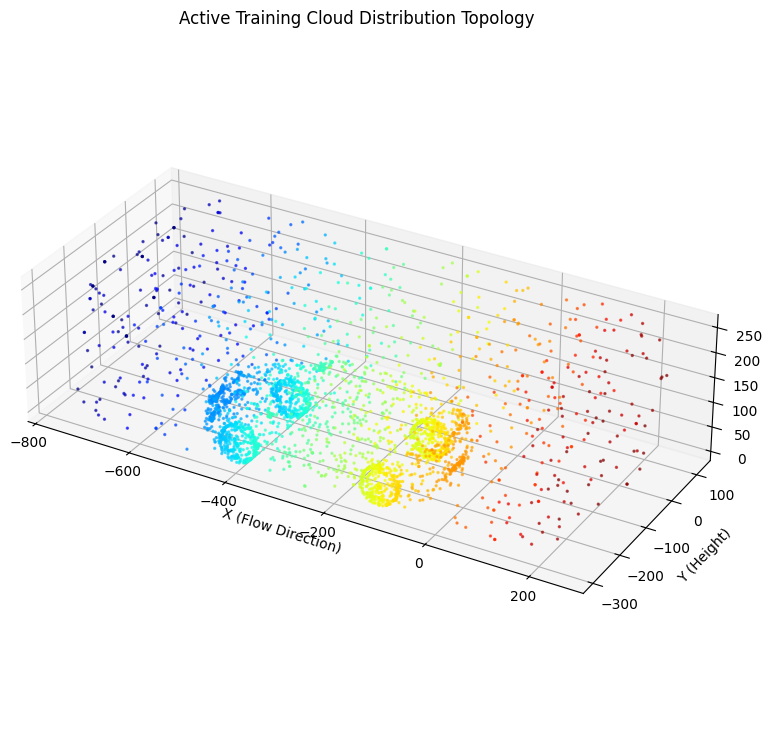

In [14]:
x_train = data.train_x

# Use a safe slicing step ONLY for the 3D viewport plotting loop 
# so your computer screen doesn't freeze up while rendering the interactive window
plot_step = max(1, len(x_train) // 3000)
visual_points = x_train[::plot_step]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Render the active point configuration
ax.scatter(
    visual_points[:, 0], visual_points[:, 1], visual_points[:, 2],
    c=visual_points[:, 0], cmap='jet', s=2, alpha=0.6
)

ax.set_xlabel('X (Flow Direction)')
ax.set_ylabel('Y (Height)')
ax.set_zlabel('Z (Width)')
ax.set_title("Active Training Cloud Distribution Topology")
ax.set_box_aspect([tunnel_xmax - tunnel_xmin, tunnel_ymax - tunnel_ymin, tunnel_zmax - tunnel_zmin])

plt.show()

Defining the Neural Network and Compiling the model

In [15]:
layer_size = [3, 128, 64, 64, 4]
net = dde.nn.FNN(layer_size, "tanh", "Glorot uniform")

model = dde.Model(data, net)


We can make Loss Weights as constants, instead we can make them adaptive So we need to create a class for generating Self Adaptive Weights through a Callback function during training

In [16]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        exp_terms = np.exp(self.alpha * np.array(current_losses))
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

Compiling the Model and Training

In [17]:
model.compile("adam", lr=1e-3, loss_weights=loss_weights)
losshistory, train_state = model.train(iterations=10000,display_every=300, callbacks=[adaptive_callback])

# dde.optimizers.config.set_LBFGS_options(maxiter=200)
model.compile("L-BFGS", loss_weights=model.loss_weights)
losshistory, train_state = model.train(display_every=50, callbacks=[adaptive_callback])




Compiling model...
'compile' took 2.098721 s

Training model...

Step      Train loss                                                                                                                                      Test loss                                                                                                                                       Test metric
0         [3.90e-03, 1.34e-03, 2.85e-03, 1.70e-03, 1.73e+00, 2.73e-01, 9.83e-02, 2.13e-01, 5.99e-01, 2.67e-01, 1.31e-01, 4.34e+01, 1.35e+01, 8.74e+00]    [3.90e-03, 1.34e-03, 2.85e-03, 1.70e-03, 1.73e+00, 2.73e-01, 9.83e-02, 2.13e-01, 5.99e-01, 2.67e-01, 1.31e-01, 4.34e+01, 1.35e+01, 8.74e+00]    []  
300       [5.19e-23, 1.38e-23, 2.63e-23, 2.08e-23, 8.69e-19, 1.61e-20, 1.28e-20, 1.27e-20, 2.06e-20, 1.79e-20, 1.95e-20, 2.32e-03, 7.17e-15, 4.67e-17]    [5.19e-23, 1.38e-23, 2.63e-23, 2.08e-23, 8.69e-19, 1.61e-20, 1.28e-20, 1.27e-20, 2.06e-20, 1.79e-20, 1.95e-20, 2.32e-03, 7.17e-15, 4.67e-17]    []  
600       [1.28e-05

Visualizing the loss history to verify optimization convergence

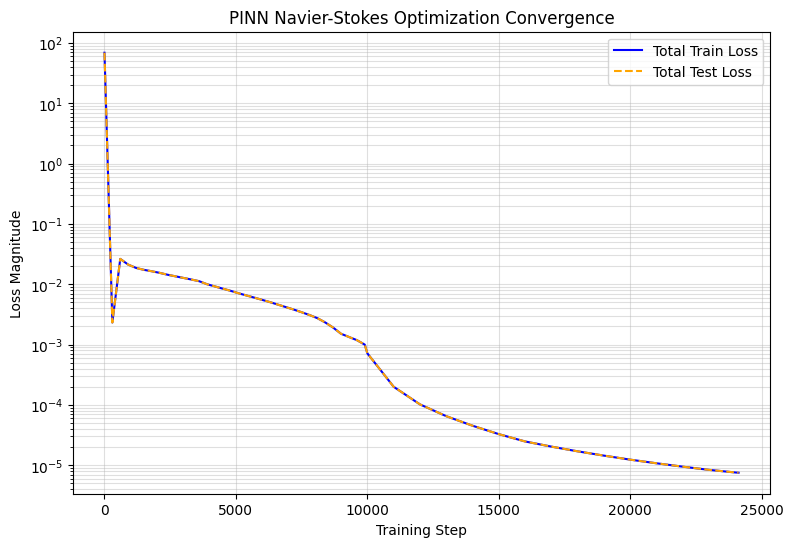

In [18]:
loss_train = np.sum(losshistory.loss_train, axis=1)
loss_test = np.sum(losshistory.loss_test, axis=1)

plt.figure(figsize=(9, 6))
plt.plot(losshistory.steps, loss_train, label="Total Train Loss", color='blue')
plt.plot(losshistory.steps, loss_test, label="Total Test Loss", linestyle='--', color='orange')
plt.yscale('log')
plt.xlabel("Training Step")
plt.ylabel("Loss Magnitude")
plt.title("PINN Navier-Stokes Optimization Convergence")
plt.grid(True, which="both", ls="-", alpha=0.4)
plt.legend()
plt.show()

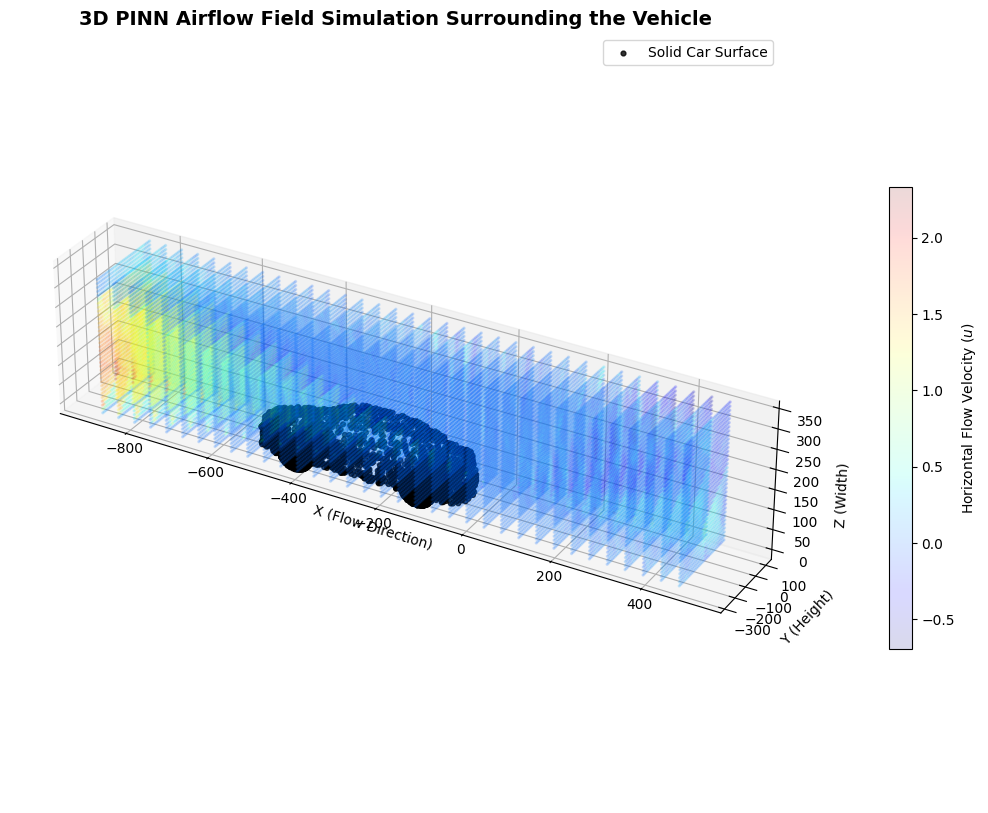

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Create a tight 3D sampling box focused strictly around the car area
# This avoids plotting the empty wind tunnel space so you can focus on the vehicle
num_points_axis = 35
x_sample = np.linspace(x_min - 0.75 * L, x_max + 1*L, num_points_axis)
y_sample = np.linspace(y_min, y_max + H, num_points_axis)
z_sample = np.linspace(z_min, z_max + W, num_points_axis)

X_m, Y_m, Z_m = np.meshgrid(x_sample, y_sample, z_sample)

# 2. Flatten into the [N, 3] matrix format expected by DeepXDE
flow_points = np.vstack((X_m.flatten(), Y_m.flatten(), Z_m.flatten())).T

# 3. Predict the velocity components using your trained network model
# predictions[:, 0] = u velocity field (flow direction)
predictions = model.predict(flow_points)
u_velocity = predictions[:, 0]

# 4. Generate the 3D Flow Field Viewport
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the air particles passing over and around the model
# Semitransparent points help you see through the air volume to see the car inside
air_scatter = ax.scatter(
    flow_points[:, 0], flow_points[:, 1], flow_points[:, 2],
    c=u_velocity, 
    cmap='jet', 
    s=2, 
    alpha=0.15
)

# 5. Overlay your fast_model_points as a solid black structural anchor
# This explicitly reveals the solid car boundary underneath the flow lines
ax.scatter(
    dense_model_points[:, 0], dense_model_points[:, 1], dense_model_points[:, 2],
    color='black', 
    s=12, 
    alpha=0.8,
    label='Solid Car Surface'
)

# 6. Add layout labels and matching scales to prevent geometric stretching
fig.colorbar(air_scatter, ax=ax, label='Horizontal Flow Velocity ($u$)', pad=0.1, shrink=0.6)
ax.set_xlabel('X (Flow Direction)')
ax.set_ylabel('Y (Height)')
ax.set_zlabel('Z (Width)')
ax.set_title('3D PINN Airflow Field Simulation Surrounding the Vehicle', fontsize=14, fontweight='bold')

# Ensure perfect spatial scaling proportion 
ax.set_box_aspect([3*L, H, 2*W])
ax.legend(loc='upper right')

plt.show()


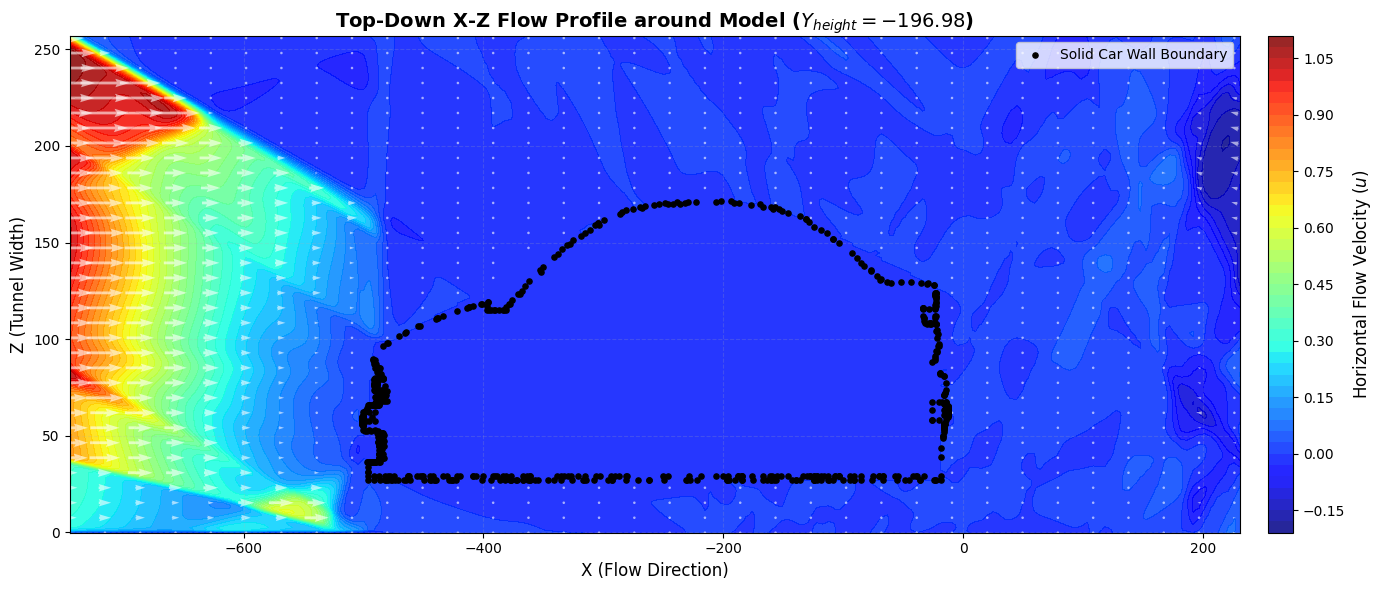

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

# 1. Target the exact middle height of your car model (Y-slice plane)
y_slice = (y_min + y_max) / 2.0

# 2. Generate a fine 2D evaluation grid along X (Flow) and Z (Width)
num_grid_points = 200
x_grid = np.linspace(tunnel_xmin, tunnel_xmax, num_grid_points)
z_grid = np.linspace(tunnel_zmin, tunnel_zmax, num_grid_points)
X_mesh, Z_mesh = np.meshgrid(x_grid, z_grid)

# 3. Flatten the mesh and hold Y constant to match DeepXDE's [N, 3] layout
X_flat = X_mesh.flatten()
Z_flat = Z_mesh.flatten()
Y_flat = np.full_like(X_flat, y_slice)

prediction_points = np.vstack((X_flat, Y_flat, Z_flat)).T

# 4. Predict the flow fields using your trained neural network
predictions = model.predict(prediction_points)
u_pred = predictions[:, 0].reshape(X_mesh.shape)
w_pred = predictions[:, 2].reshape(X_mesh.shape)

# 5. GEOMETRIC MASKING: Cleanly isolate the car footprint interior using ConvexHull + Matplotlib Path
y_tol = (y_max - y_min) * 0.15
car_slice_nodes = dense_model_points[np.abs(dense_model_points[:, 1] - y_slice) < y_tol]

if len(car_slice_nodes) > 3:
    from scipy.spatial import ConvexHull
    points_2d = car_slice_nodes[:, [0, 2]]  # Keep only X and Z coordinates
    hull = ConvexHull(points_2d)
    
    # Extract the boundary vertices in correct cyclic order
    hull_vertices = points_2d[hull.vertices]
    
    # FIX: Use matplotlib.path.Path to build the polygon check geometry
    hull_path = Path(hull_vertices)
    
    # Evaluate every grid node coordinate
    grid_coords = np.vstack((X_flat, Z_flat)).T
    is_inside_car = hull_path.contains_points(grid_coords).reshape(X_mesh.shape)
    
    # Zero out the velocities exactly within the solid body structure
    u_pred[is_inside_car] = 0.0
    w_pred[is_inside_car] = 0.0
else:
    is_inside_car = np.zeros_like(X_mesh, dtype=bool)

# 6. Render the top-down horizontal velocity contour map
plt.figure(figsize=(15, 6))
contour = plt.contourf(X_mesh, Z_mesh, u_pred, levels=50, cmap='jet', alpha=0.85)
cbar = plt.colorbar(contour, pad=0.02)
cbar.set_label('Horizontal Flow Velocity ($u$)', fontsize=12)

# 7. Plot Vector Arrows (Quivers) around the masked profile
u_quiver = np.where(is_inside_car, np.nan, u_pred)
w_quiver = np.where(is_inside_car, np.nan, w_pred)

stride = 6
plt.quiver(
    X_mesh[::stride, ::stride], 
    Z_mesh[::stride, ::stride], 
    u_quiver[::stride, ::stride], 
    w_quiver[::stride, ::stride], 
    color='white', 
    alpha=0.6, 
    scale=25, 
    pivot='mid'
)

# 8. Overlay the solid car geometry points directly on top
plt.scatter(
    car_slice_nodes[:, 0], 
    car_slice_nodes[:, 2], 
    color='black', 
    s=14, 
    label='Solid Car Wall Boundary', 
    zorder=10
)

# 9. Clean up visual boundaries and text labels
plt.xlabel('X (Flow Direction)', fontsize=12)
plt.ylabel('Z (Tunnel Width)', fontsize=12)
plt.title(f'Top-Down X-Z Flow Profile around Model ($Y_{{height}} = {y_slice:.2f}$)', fontsize=14, fontweight='bold')
plt.xlim(tunnel_xmin, tunnel_xmax)
plt.ylim(z_min, tunnel_zmax)
plt.grid(True, linestyle='--', alpha=0.2)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
